In [1]:
import os

dataset_path = "raw_dataset"

print("Dataset exists:", os.path.exists(dataset_path))
print("Folders:", os.listdir(dataset_path))

Dataset exists: True
Folders: []


In [2]:
import os

for root, dirs, files in os.walk("."):
    print(root, dirs, files[:5])

. ['.ipynb_checkpoints', 'raw_dataset'] ['NeuroGuard_Training.ipynb', 'Untitled.ipynb']
.\.ipynb_checkpoints [] ['NeuroGuard_Training-checkpoint.ipynb', 'Untitled-checkpoint.ipynb']
.\raw_dataset [] []


In [3]:
import os

dataset_path = "raw_dataset"

print("Folders:", os.listdir(dataset_path))

Folders: ['dataset_new']


In [4]:
import os

path = "raw_dataset/dataset_new"

print("Folders:", os.listdir(path))

for root, dirs, files in os.walk(path):
    print(root, "| Images:", len(files))

Folders: ['test', 'train']
raw_dataset/dataset_new | Images: 0
raw_dataset/dataset_new\test | Images: 0
raw_dataset/dataset_new\test\Closed | Images: 109
raw_dataset/dataset_new\test\no_yawn | Images: 109
raw_dataset/dataset_new\test\Open | Images: 109
raw_dataset/dataset_new\test\yawn | Images: 106
raw_dataset/dataset_new\train | Images: 0
raw_dataset/dataset_new\train\Closed | Images: 617
raw_dataset/dataset_new\train\no_yawn | Images: 616
raw_dataset/dataset_new\train\Open | Images: 617
raw_dataset/dataset_new\train\yawn | Images: 617


In [5]:
import os
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "raw_dataset" / "dataset_new"

print("Project folder:", PROJECT_DIR)
print("Dataset exists:", DATASET_DIR.exists())

assert DATASET_DIR.exists(), "Dataset folder not found!"

classes = ["Closed", "Open", "no_yawn", "yawn"]

for split in ["train", "test"]:
    print("\n", split.upper())

    for cls in classes:
        folder = DATASET_DIR / split / cls

        assert folder.exists(), f"Missing folder: {folder}"

        images = [
            f for f in folder.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
        ]

        print(cls, ":", len(images))

Project folder: C:\Users\avina\OneDrive\Desktop\neuroguard
Dataset exists: True

 TRAIN
Closed : 617
Open : 617
no_yawn : 616
yawn : 617

 TEST
Closed : 109
Open : 109
no_yawn : 109
yawn : 106


In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import mediapipe as mp
import os

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)

IMG_SIZE = (96, 96)
BATCH_SIZE = 32
SEED = 42

AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.17.1
NumPy: 1.26.4
OpenCV: 4.11.0
MediaPipe: 0.10.21


In [7]:
train_full = tf.keras.utils.image_dataset_from_directory(
    str(DATASET_DIR / "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["Closed", "Open", "no_yawn", "yawn"],
    validation_split=0.20,
    subset="training",
    seed=SEED
)

val_full = tf.keras.utils.image_dataset_from_directory(
    str(DATASET_DIR / "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["Closed", "Open", "no_yawn", "yawn"],
    validation_split=0.20,
    subset="validation",
    seed=SEED
)

test_full = tf.keras.utils.image_dataset_from_directory(
    str(DATASET_DIR / "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["Closed", "Open", "no_yawn", "yawn"],
    shuffle=False
)

print("Class names:", train_full.class_names)

Found 2467 files belonging to 4 classes.
Using 1974 files for training.
Found 2467 files belonging to 4 classes.
Using 493 files for validation.
Found 433 files belonging to 4 classes.
Class names: ['Closed', 'Open', 'no_yawn', 'yawn']


In [8]:
def create_binary_dataset(dataset, task):

    dataset = dataset.unbatch()

    if task == "eye":
        dataset = dataset.filter(
            lambda x, y: y < 2
        )

        dataset = dataset.map(
            lambda x, y: (x, tf.cast(y, tf.int32)),
            num_parallel_calls=AUTOTUNE
        )

    elif task == "mouth":
        dataset = dataset.filter(
            lambda x, y: y >= 2
        )

        dataset = dataset.map(
            lambda x, y: (
                x,
                tf.cast(y - 2, tf.int32)
            ),
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


eye_train = create_binary_dataset(train_full, "eye")
eye_val = create_binary_dataset(val_full, "eye")
eye_test = create_binary_dataset(test_full, "eye")

mouth_train = create_binary_dataset(train_full, "mouth")
mouth_val = create_binary_dataset(val_full, "mouth")
mouth_test = create_binary_dataset(test_full, "mouth")

print("Eye and mouth datasets created successfully!")

Eye and mouth datasets created successfully!


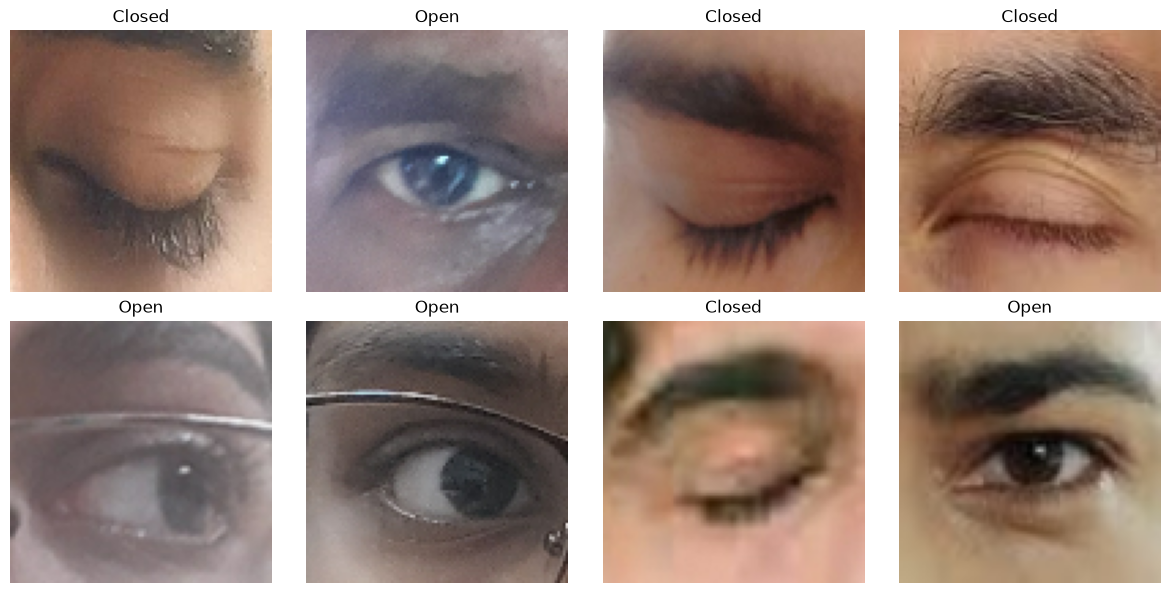

In [9]:
plt.figure(figsize=(12, 6))

for images, labels in eye_train.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(["Closed", "Open"][int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
def build_cnn_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(96, 96, 3)
        ),

        tf.keras.layers.Rescaling(1./255),

        tf.keras.layers.RandomFlip("horizontal"),

        tf.keras.layers.RandomRotation(0.03),

        tf.keras.layers.Conv2D(
            32, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            64, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(
            128, 3, activation="relu"
        ),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dense(
            64, activation="relu"
        ),

        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Dense(
            2, activation="softmax"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


eye_model = build_cnn_model()
mouth_model = build_cnn_model()

print("Both CNN models created!")

Both CNN models created!


In [11]:
eye_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_flip (RandomFlip)             │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 94, 94, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 47, 47, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 45, 45, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 22, 22, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 20, 20, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 10, 10, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,634 (397.01 KB)

 Trainable params: 101,634 (397.01 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
callbacks_eye = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=1,
        factor=0.5,
        min_lr=0.00001
    )
]

eye_history = eye_model.fit(
    eye_train,
    validation_data=eye_val,
    epochs=6,
    callbacks=callbacks_eye
)

Epoch 1/6


C:\Users\avina\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


     31/Unknown 19s 437ms/step - accuracy: 0.5592 - loss: 0.6912

C:\Users\avina\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 509ms/step - accuracy: 0.5592 - loss: 0.6912 - val_accuracy: 0.5633 - val_loss: 0.6657 - learning_rate: 0.0010
Epoch 2/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 523ms/step - accuracy: 0.5784 - loss: 0.6703 - val_accuracy: 0.6245 - val_loss: 0.6243 - learning_rate: 0.0010
Epoch 3/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 630ms/step - accuracy: 0.7017 - loss: 0.6089 - val_accuracy: 0.6857 - val_loss: 0.5751 - learning_rate: 0.0010
Epoch 4/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 657ms/step - accuracy: 0.7553 - loss: 0.5226 - val_accuracy: 0.7673 - val_loss: 0.4684 - learning_rate: 0.0010
Epoch 5/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 14s 432ms/step - accuracy: 0.8150 - loss: 0.4456 - val_accuracy: 0.8000 - val_loss: 0.4985 - learning_rate: 0.0010
Epoch 6/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 26s 439ms/step - accuracy: 0.8311 - loss: 0.4064 - val_accuracy: 0.8286 - val_loss: 0.3744 - learning_rate: 5.0000e-04


In [13]:
eye_loss, eye_accuracy = eye_model.evaluate(eye_test)

print("Eye Test Accuracy:", round(eye_accuracy * 100, 2), "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 288ms/step - accuracy: 0.8257 - loss: 0.4066
Eye Test Accuracy: 82.57 %


In [14]:
callbacks_mouth = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=1,
        factor=0.5,
        min_lr=0.00001
    )  
]

mouth_history = mouth_model.fit(
    mouth_train,
    validation_data=mouth_val,
    epochs=6,
    callbacks=callbacks_mouth
)

Epoch 1/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 462ms/step - accuracy: 0.4975 - loss: 0.6969 - val_accuracy: 0.5968 - val_loss: 0.6920 - learning_rate: 0.0010
Epoch 2/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 455ms/step - accuracy: 0.5360 - loss: 0.6891 - val_accuracy: 0.5000 - val_loss: 0.6912 - learning_rate: 0.0010
Epoch 3/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 28s 704ms/step - accuracy: 0.5848 - loss: 0.6704 - val_accuracy: 0.4960 - val_loss: 0.7034 - learning_rate: 0.0010
Epoch 4/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 41s 692ms/step - accuracy: 0.6162 - loss: 0.6392 - val_accuracy: 0.5806 - val_loss: 0.6678 - learning_rate: 5.0000e-04
Epoch 5/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 655ms/step - accuracy: 0.6335 - loss: 0.6134 - val_accuracy: 0.5806 - val_loss: 0.7654 - learning_rate: 5.0000e-04
Epoch 6/6
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 466ms/step - accuracy: 0.6254 - loss: 0.6089 - val_accuracy: 0.5806 - val_loss: 0.7235 - learning_rate: 2.5000e-04


In [15]:
mouth_loss, mouth_accuracy = mouth_model.evaluate(mouth_test)

print(
    "Mouth Test Accuracy:",
    round(mouth_accuracy * 100, 2),
    "%"
)

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 152ms/step - accuracy: 0.5442 - loss: 0.6667
Mouth Test Accuracy: 54.42 %


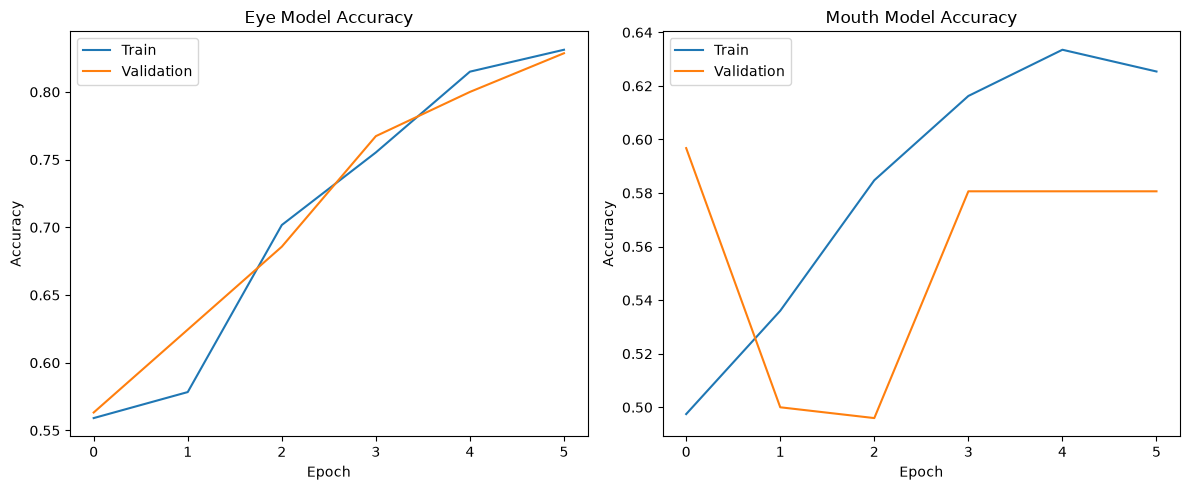

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(eye_history.history["accuracy"], label="Train")
plt.plot(eye_history.history["val_accuracy"], label="Validation")
plt.title("Eye Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mouth_history.history["accuracy"], label="Train")
plt.plot(mouth_history.history["val_accuracy"], label="Validation")
plt.title("Mouth Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


In [17]:
eye_model.save("eye_model.keras")

mouth_model.save("mouth_model.keras")

print("Eye model saved successfully!")
print("Mouth model saved successfully!")


Eye model saved successfully!
Mouth model saved successfully!


In [18]:
loaded_eye = tf.keras.models.load_model(
    "eye_model.keras"
)

loaded_mouth = tf.keras.models.load_model(
    "mouth_model.keras"
)

print("Both saved models loaded successfully!")

Both saved models loaded successfully!


In [19]:
%%writefile webcam_app.py

import cv2
import mediapipe as mp
import numpy as np
import tensorflow as tf
import time

from collections import deque


# ====================================
# 1. LOAD TRAINED MODELS
# ====================================

eye_model = tf.keras.models.load_model(
    "eye_model.keras"
)

mouth_model = tf.keras.models.load_model(
    "mouth_model.keras"
)

IMG_SIZE = (96, 96)


# ====================================
# 2. MEDIAPIPE INITIALIZATION
# ====================================

mp_face_mesh = mp.solutions.face_mesh

face_mesh = mp_face_mesh.FaceMesh(
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
)


# ====================================
# 3. LANDMARK INDICES
# ====================================

LEFT_EYE = [
    33, 133, 160, 159, 158, 157,
    173, 144, 145, 153, 154, 155
]

RIGHT_EYE = [
    362, 263, 387, 386, 385, 384,
    398, 373, 374, 380, 381, 382
]

MOUTH = [
    61, 291, 0, 17, 13, 14, 78, 308
]


# ====================================
# 4. CROP FACIAL REGION
# ====================================

def get_crop(frame, landmarks, indices, padding=0.35):

    h, w = frame.shape[:2]

    points = [
        landmarks[i] for i in indices
    ]

    xs = [int(p.x * w) for p in points]
    ys = [int(p.y * h) for p in points]

    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)

    pad_x = max(3, int((x_max - x_min) * padding))
    pad_y = max(3, int((y_max - y_min) * padding))

    x1 = max(0, x_min - pad_x)
    y1 = max(0, y_min - pad_y)

    x2 = min(w, x_max + pad_x)
    y2 = min(h, y_max + pad_y)

    if x2 <= x1 or y2 <= y1:
        return None

    crop = frame[y1:y2, x1:x2]

    if crop.size == 0:
        return None

    return crop


# ====================================
# 5. PREPARE MODEL INPUT
# ====================================

def prepare_image(crop):

    crop = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2RGB
    )

    crop = cv2.resize(
        crop,
        IMG_SIZE
    )

    return crop


# ====================================
# 6. WEBCAM START
# ====================================

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not cap.isOpened():
    cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError(
        "Webcam not detected. Check camera connection."
    )


# ====================================
# 7. DROWSINESS SETTINGS
# ====================================

CLOSED_THRESHOLD = 0.65
YAWN_THRESHOLD = 0.65

CLOSED_DURATION = 1.5

closed_since = None

eye_history = deque(maxlen=5)
yawn_history = deque(maxlen=5)


print("NeuroGuard AI Started!")
print("Press Q to quit.")


# ====================================
# 8. MAIN WEBCAM LOOP
# ====================================

try:

    while True:

        success, frame = cap.read()

        if not success:
            print("Cannot read webcam frame.")
            break

        frame = cv2.flip(frame, 1)

        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        results = face_mesh.process(rgb_frame)

        status = "NORMAL"
        color = (0, 255, 0)

        if results.multi_face_landmarks:

            landmarks = results.multi_face_landmarks[0].landmark

            # Get eye crops

            left_crop = get_crop(
                frame, landmarks, LEFT_EYE
            )

            right_crop = get_crop(
                frame, landmarks, RIGHT_EYE
            )

            mouth_crop = get_crop(
                frame, landmarks, MOUTH, padding=0.6
            )

            eye_crops = []

            if left_crop is not None:
                eye_crops.append(
                    prepare_image(left_crop)
                )

            if right_crop is not None:
                eye_crops.append(
                    prepare_image(right_crop)
                )

            if len(eye_crops) > 0:

                eye_batch = np.array(eye_crops)

                eye_predictions = eye_model.predict(
                    eye_batch,
                    verbose=0
                )

                closed_probability = float(
                    np.mean(1.0 - eye_predictions[:, 1])
                )

                eye_history.append(closed_probability)

                avg_closed = float(
                    np.mean(eye_history)
                )

            else:
                avg_closed = 0.0

            # Mouth prediction

            if mouth_crop is not None:

                mouth_input = prepare_image(
                    mouth_crop
                )

                mouth_input = np.expand_dims(
                    mouth_input,
                    axis=0
                )

                mouth_prediction = mouth_model.predict(
                    mouth_input,
                    verbose=0
                )[0]

                yawn_probability = float(
                    mouth_prediction[1]
                )

                yawn_history.append(
                    yawn_probability
                )

                avg_yawn = float(
                    np.mean(yawn_history)
                )

            else:
                avg_yawn = 0.0

            # Closed eye detection

            if avg_closed >= CLOSED_THRESHOLD:

                if closed_since is None:
                    closed_since = time.time()

                closed_duration = (
                    time.time() - closed_since
                )

                if closed_duration >= CLOSED_DURATION:

                    status = "DROWSINESS ALERT!"
                    color = (0, 0, 255)

            else:
                closed_since = None

            # Yawning detection

            if avg_yawn >= YAWN_THRESHOLD:

                status = "YAWNING DETECTED"
                color = (0, 165, 255)

            # Display probabilities

            cv2.putText(
                frame,
                f"Eyes Closed: {avg_closed:.2f}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                color,
                2
            )

            cv2.putText(
                frame,
                f"Yawning: {avg_yawn:.2f}",
                (20, 75),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                color,
                2
            )

        else:

            status = "FACE NOT DETECTED"
            color = (0, 165, 255)

            closed_since = None
            eye_history.clear()
            yawn_history.clear()

        # Display status

        cv2.putText(
            frame,
            status,
            (20, 125),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            color,
            2
        )

        cv2.imshow(
            "NeuroGuard AI - Driver Drowsiness Detection",
            frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break


finally:

    cap.release()
    face_mesh.close()
    cv2.destroyAllWindows()

    print("NeuroGuard AI stopped.")

Writing webcam_app.py


In [20]:
import os

print("File exists:", os.path.exists("webcam_app.py"))
print("File size:", os.path.getsize("webcam_app.py"), "bytes")

File exists: True
File size: 7388 bytes
